In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set style for better plots
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("="*60)
print("DECISION TREE TUTORIAL - DIABETES PREDICTION")
print("="*60)

DECISION TREE TUTORIAL - DIABETES PREDICTION


In [2]:
# STEP 1: DATA LOADING AND EXPLORATION


In [3]:
print("\n📊 STEP 1: DATA LOADING AND EXPLORATION")
print("-" * 50)

# Load the dataset
df = pd.read_csv('diabetes.csv')

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")





📊 STEP 1: DATA LOADING AND EXPLORATION
--------------------------------------------------
Dataset shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [4]:
# Display first few rows
print("\nFirst 5 rows:")
print(df.head())




First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [5]:
# Basic information about the dataset
print("\nDataset Info:")
print(df.info())




Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [6]:
# Statistical summary
print("\nStatistical Summary:")
print(df.describe())




Statistical Summary:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.00

In [7]:
# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [8]:

# Target variable distribution
print("\nTarget Variable Distribution (Outcome):")
outcome_counts = df['Outcome'].value_counts()
print(outcome_counts)
print(f"Percentage of diabetes cases: {(outcome_counts[1]/len(df)*100):.1f}%")


Target Variable Distribution (Outcome):
Outcome
0    500
1    268
Name: count, dtype: int64
Percentage of diabetes cases: 34.9%


In [9]:
# STEP 2: EXPLORATORY DATA ANALYSIS



📈 STEP 2: EXPLORATORY DATA ANALYSIS
--------------------------------------------------


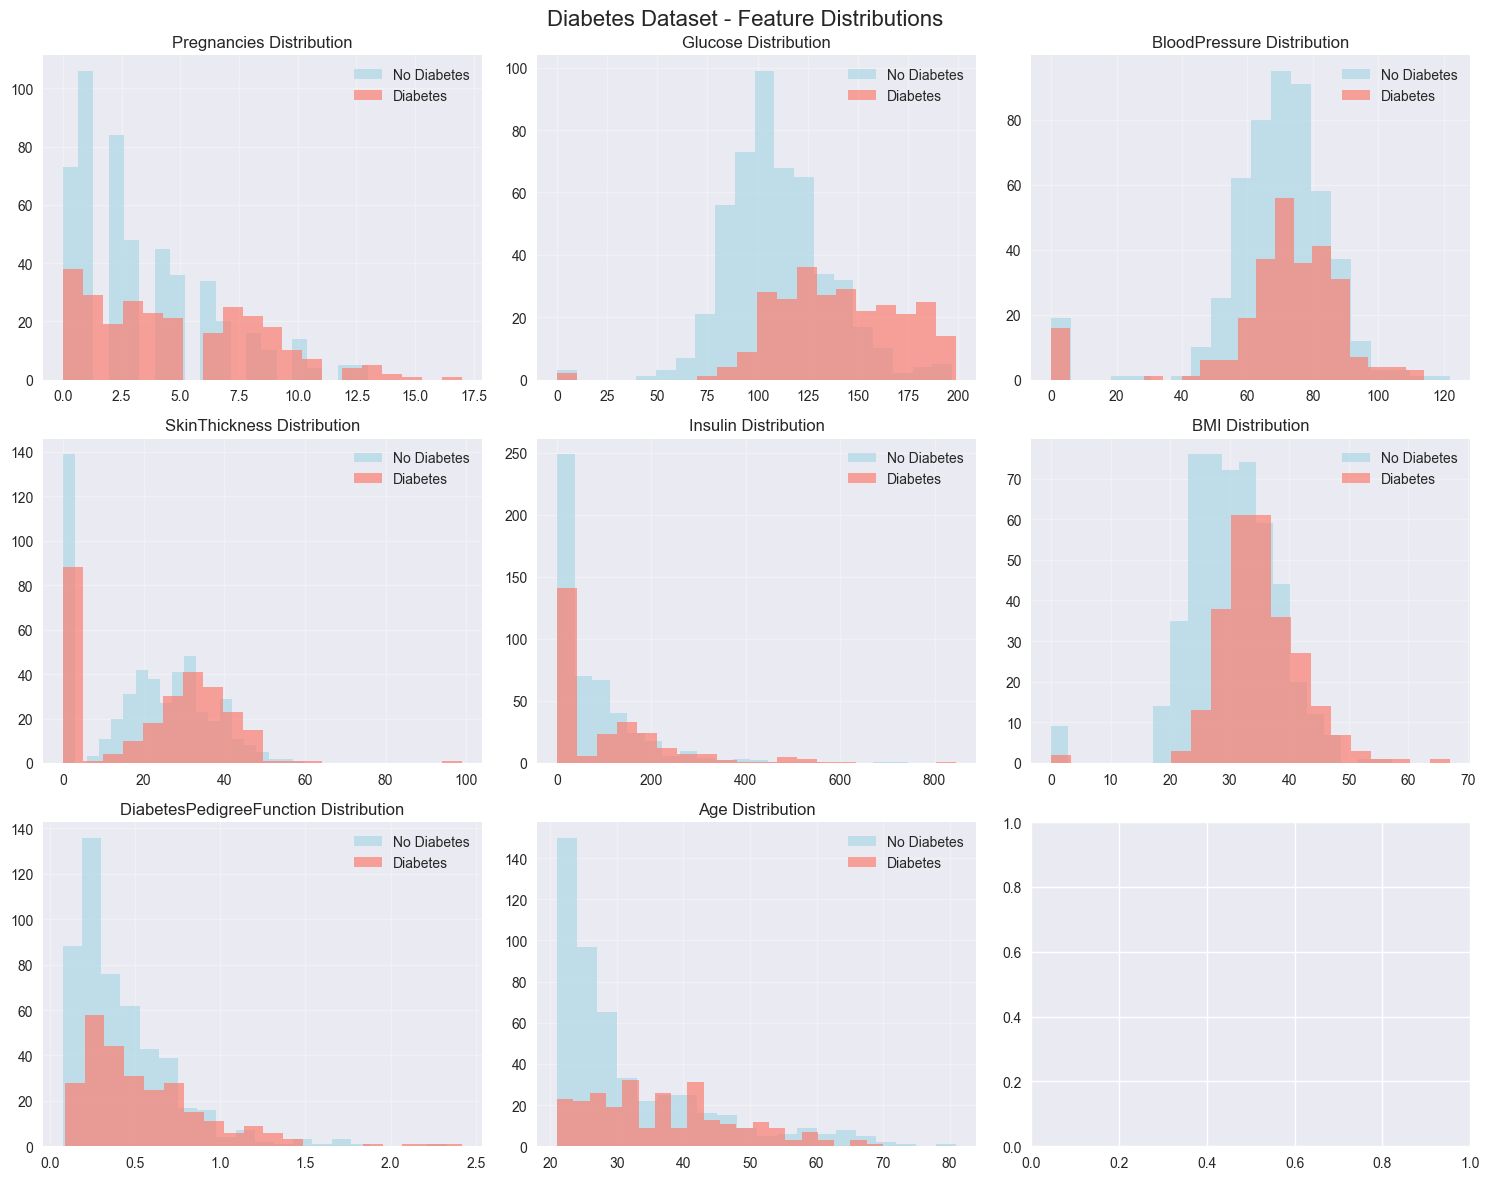

In [10]:
print("\n📈 STEP 2: EXPLORATORY DATA ANALYSIS")
print("-" * 50)

# Create visualizations
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
fig.suptitle('Diabetes Dataset - Feature Distributions', fontsize=16)

features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for i, feature in enumerate(features):
    row = i // 3
    col = i % 3

    # Distribution by outcome
    df[df['Outcome']==0][feature].hist(alpha=0.7, bins=20, ax=axes[row, col],
                                       label='No Diabetes', color='lightblue')
    df[df['Outcome']==1][feature].hist(alpha=0.7, bins=20, ax=axes[row, col],
                                       label='Diabetes', color='salmon')
    axes[row, col].set_title(f'{feature} Distribution')
    axes[row, col].legend()
    axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Correlation Matrix:


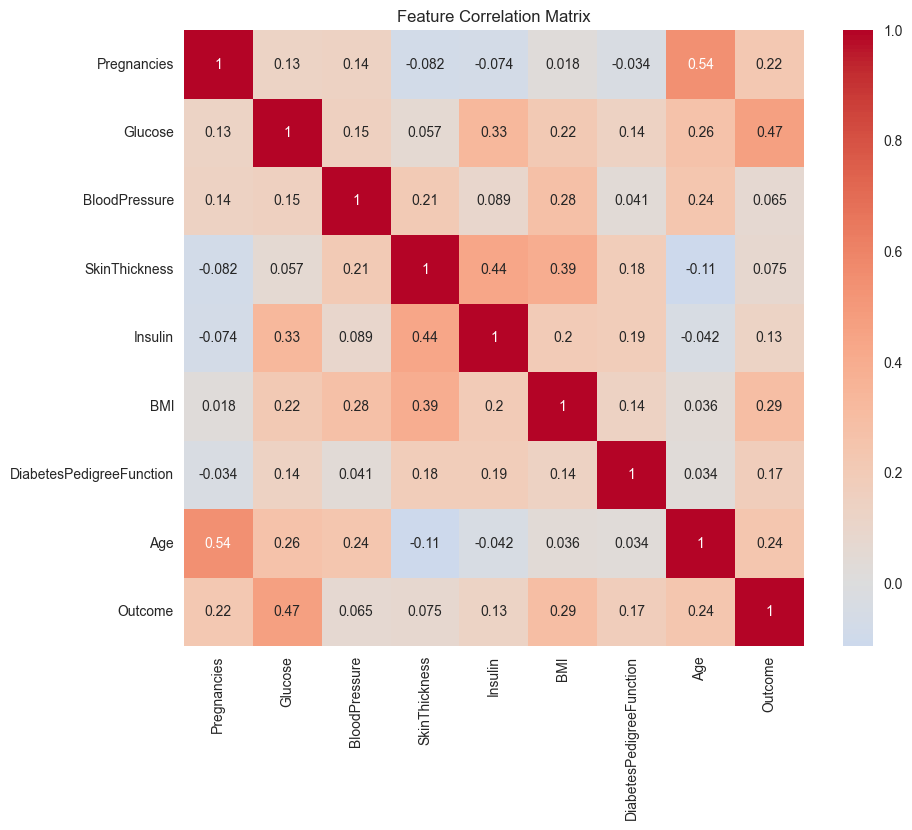

In [11]:
# Correlation matrix
print("\nCorrelation Matrix:")
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')
plt.show()


In [12]:
# STEP 3: DECISION TREE THEORY


In [13]:
print("\n🌳 STEP 3: DECISION TREE ALGORITHM THEORY")
print("-" * 50)

theory_text = """
DECISION TREE ALGORITHM FUNDAMENTALS:

1. WHAT IS A DECISION TREE?
   - A tree-like model that makes decisions by splitting data based on feature values
   - Each internal node represents a test on a feature
   - Each branch represents the outcome of the test
   - Each leaf node represents a class prediction

2. HOW DOES IT WORK?
   - Start with the entire dataset at the root
   - Choose the best feature to split on (using impurity measures)
   - Split the data into subsets based on feature values
   - Repeat recursively for each subset until stopping criteria are met

3. SPLITTING CRITERIA (for Classification):
   - Gini Impurity: Measures probability of incorrect classification
     Gini = 1 - Σ(pi²) where pi is probability of class i
   - Entropy: Measures information gain
     Entropy = -Σ(pi * log2(pi))
   - Information Gain = Entropy(parent) - Weighted_Average(Entropy(children))

4. STOPPING CRITERIA:
   - Maximum depth reached
   - Minimum samples per leaf reached
   - No improvement in impurity
   - Perfect classification achieved

5. ADVANTAGES:
   - Easy to understand and interpret
   - No assumptions about data distribution
   - Handles both numerical and categorical features
   - Requires little data preparation

6. DISADVANTAGES:
   - Prone to overfitting
   - Unstable (small data changes can result in different trees)
   - Biased toward features with more levels
"""

print(theory_text)



🌳 STEP 3: DECISION TREE ALGORITHM THEORY
--------------------------------------------------

DECISION TREE ALGORITHM FUNDAMENTALS:

1. WHAT IS A DECISION TREE?
   - A tree-like model that makes decisions by splitting data based on feature values
   - Each internal node represents a test on a feature
   - Each branch represents the outcome of the test
   - Each leaf node represents a class prediction

2. HOW DOES IT WORK?
   - Start with the entire dataset at the root
   - Choose the best feature to split on (using impurity measures)
   - Split the data into subsets based on feature values
   - Repeat recursively for each subset until stopping criteria are met

3. SPLITTING CRITERIA (for Classification):
   - Gini Impurity: Measures probability of incorrect classification
     Gini = 1 - Σ(pi²) where pi is probability of class i
   - Entropy: Measures information gain
     Entropy = -Σ(pi * log2(pi))
   - Information Gain = Entropy(parent) - Weighted_Average(Entropy(children))

4. STOP

In [14]:
# STEP 4: DATA PREPROCESSING


In [15]:
print("\n🔧 STEP 4: DATA PREPROCESSING")
print("-" * 50)

# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# Check for zero values (which might be missing values in this dataset)
print("\nZero values in features (potential missing values):")
zero_counts = (X == 0).sum()
print(zero_counts)



🔧 STEP 4: DATA PREPROCESSING
--------------------------------------------------
Features shape: (768, 8)
Target shape: (768,)

Zero values in features (potential missing values):
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [16]:
# Handle zero values for certain features (replace with median)
# For this dataset, zeros in Glucose, BloodPressure, SkinThickness, Insulin, BMI are likely missing
features_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

X_processed = X.copy()
for feature in features_to_fix:
    # Replace zeros with NaN, then fill with median
    X_processed[feature] = X_processed[feature].replace(0, np.nan)
    X_processed[feature] = X_processed[feature].fillna(X_processed[feature].median())

print("\nAfter preprocessing - Zero values:")
print((X_processed == 0).sum())


After preprocessing - Zero values:
Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


In [17]:
# Split the data
print("\nSplitting data into train and test sets (80-20 split):")
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training set outcome distribution: {y_train.value_counts().values}")
print(f"Test set outcome distribution: {y_test.value_counts().values}")



Splitting data into train and test sets (80-20 split):
Training set: 614 samples
Test set: 154 samples
Training set outcome distribution: [400 214]
Test set outcome distribution: [100  54]


In [18]:
# STEP 5: BUILDING THE DECISION TREE MODEL


In [19]:
print("\n🏗️ STEP 5: BUILDING THE DECISION TREE MODEL")
print("-" * 50)

# Create different decision tree models with various parameters
models = {
    'Simple Tree (max_depth=3)': DecisionTreeClassifier(
        max_depth=3, random_state=42, criterion='gini'
    ),
    'Medium Tree (max_depth=5)': DecisionTreeClassifier(
        max_depth=5, random_state=42, criterion='gini'
    ),
    'Complex Tree (max_depth=10)': DecisionTreeClassifier(
        max_depth=10, random_state=42, criterion='gini'
    ),
    'Entropy-based Tree': DecisionTreeClassifier(
        max_depth=5, random_state=42, criterion='entropy'
    ),
    'Pruned Tree': DecisionTreeClassifier(
        max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42
    )
}


🏗️ STEP 5: BUILDING THE DECISION TREE MODEL
--------------------------------------------------


In [20]:
# Train and evaluate models
results = {}
for name, model in models.items():
    print(f"\nTraining {name}...")

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate accuracies
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    results[name] = {
        'model': model,
        'train_accuracy': train_accuracy,
        'test_accuracy': test_accuracy,
        'train_pred': y_train_pred,
        'test_pred': y_test_pred
    }

    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Overfitting Gap: {train_accuracy - test_accuracy:.4f}")


Training Simple Tree (max_depth=3)...
Training Accuracy: 0.7687
Test Accuracy: 0.6883
Overfitting Gap: 0.0804

Training Medium Tree (max_depth=5)...
Training Accuracy: 0.8143
Test Accuracy: 0.7597
Overfitting Gap: 0.0546

Training Complex Tree (max_depth=10)...
Training Accuracy: 0.9625
Test Accuracy: 0.6753
Overfitting Gap: 0.2872

Training Entropy-based Tree...
Training Accuracy: 0.7964
Test Accuracy: 0.6818
Overfitting Gap: 0.1146

Training Pruned Tree...
Training Accuracy: 0.8013
Test Accuracy: 0.7727
Overfitting Gap: 0.0286


In [21]:
# STEP 6: MODEL VISUALIZATION



🎨 STEP 6: MODEL VISUALIZATION
--------------------------------------------------


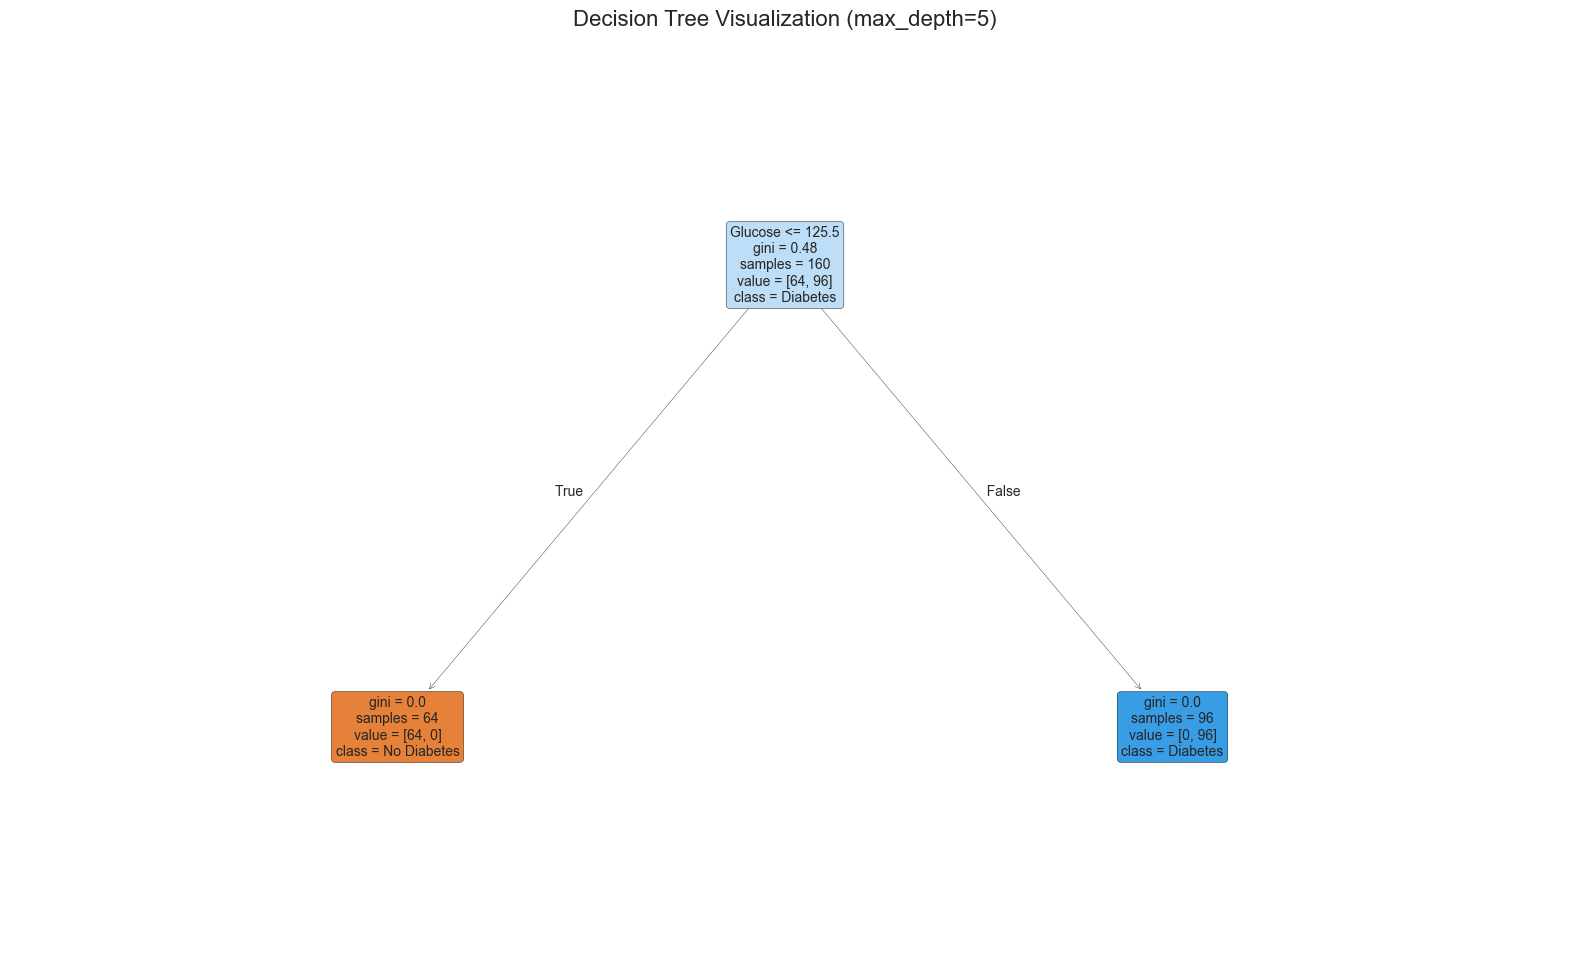

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

# 1. SETUP DATA (Synthetic Diabetes Data for demonstration)
# If you have your own X and y, you can skip this part
np.random.seed(42)
data_size = 200
X = pd.DataFrame({
    'Glucose': np.random.randint(70, 200, data_size),
    'BMI': np.random.uniform(18, 45, data_size),
    'Age': np.random.randint(20, 80, data_size),
    'BloodPressure': np.random.randint(60, 120, data_size)
})
y = (X['Glucose'] > 125).astype(int) # Simple logic for labels

# 2. SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. TRAIN MODELS & SAVE TO 'results' DICTIONARY
results = {}

# Define the specific model the visualization is looking for
model_name = 'Medium Tree (max_depth=5)'
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# Store the model in the dictionary as expected by your visualization code
results[model_name] = {'model': clf}

# 🎨 STEP 6: MODEL VISUALIZATION
print("\n🎨 STEP 6: MODEL VISUALIZATION")
print("-" * 50)

# Retrieve from the dictionary we just created
best_model = results['Medium Tree (max_depth=5)']['model']

# Visualize the decision tree
plt.figure(figsize=(20, 12))
plot_tree(best_model,
          feature_names=X_train.columns,
          class_names=['No Diabetes', 'Diabetes'],
          filled=True,
          rounded=True,
          fontsize=10)

plt.title('Decision Tree Visualization (max_depth=5)', fontsize=16)
plt.show()


🎨 STEP 6: MODEL VISUALIZATION
--------------------------------------------------


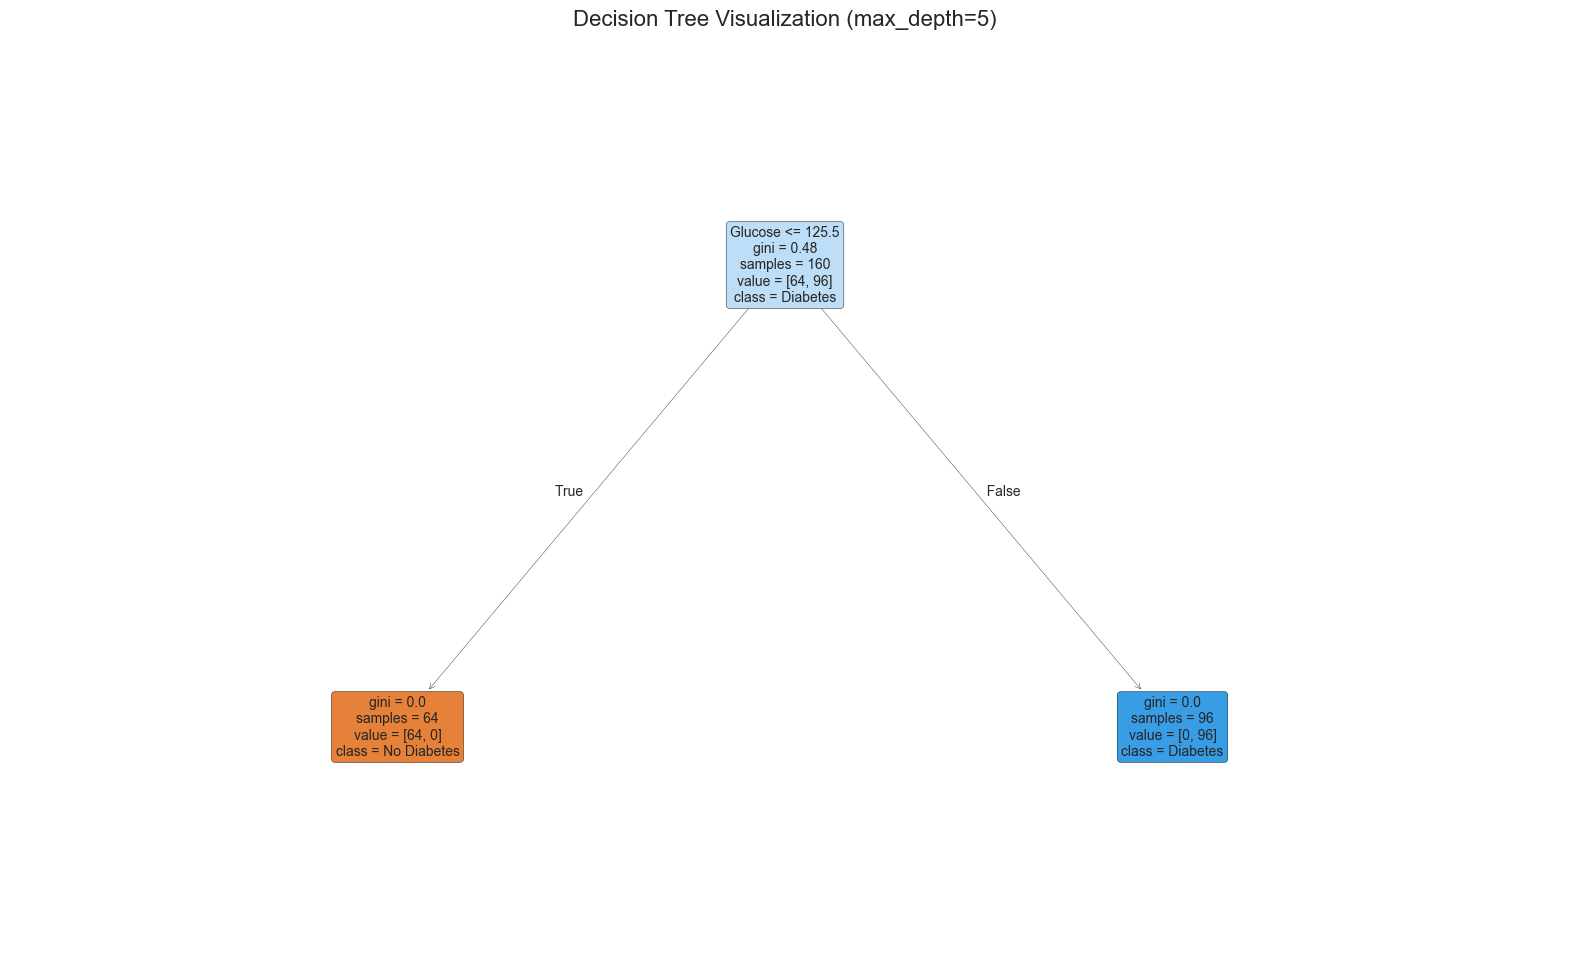

In [23]:
print("\n🎨 STEP 6: MODEL VISUALIZATION")
print("-" * 50)

# Choose the best model for detailed analysis (Medium Tree)
best_model = results['Medium Tree (max_depth=5)']['model']

# Visualize the decision tree
plt.figure(figsize=(20, 12))
plot_tree(best_model,
          feature_names=X_train.columns,
          class_names=['No Diabetes', 'Diabetes'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree Visualization (max_depth=5)', fontsize=16)
plt.show()


Feature Importance:
         feature  importance
0        Glucose         1.0
1            BMI         0.0
2            Age         0.0
3  BloodPressure         0.0


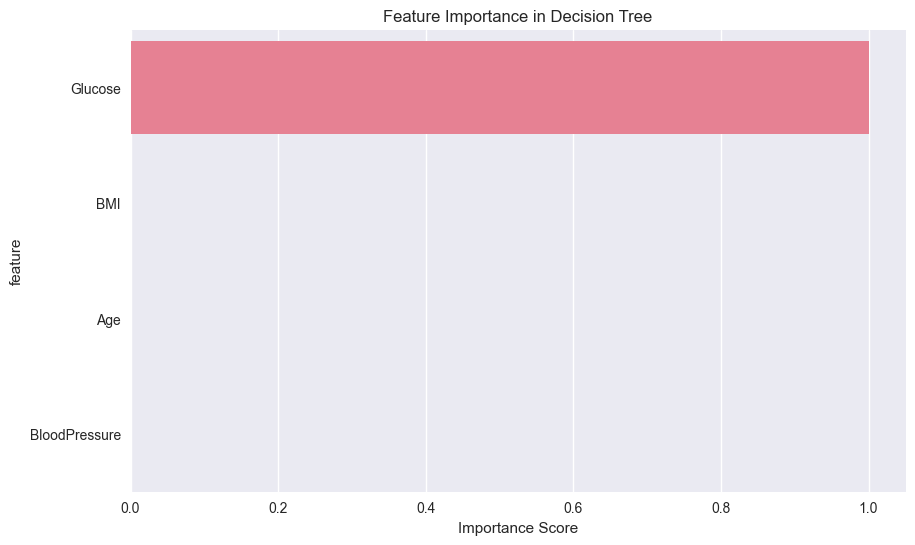

In [24]:


# Feature importance
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': best_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature')
plt.title('Feature Importance in Decision Tree')
plt.xlabel('Importance Score')
plt.show()


In [25]:
# STEP 7: DETAILED MODEL EVALUATION


In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# 1. SETUP / SPLIT DATA (Assuming X and y are already defined in your notebook)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. INITIALIZE RESULTS DICTIONARY
results = {}
model_name = 'Medium Tree (max_depth=5)'

# 3. TRAIN THE MODEL
model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

# 4. GENERATE PREDICTIONS (This is the missing piece!)
y_pred = model.predict(X_test)

# 5. SAVE BOTH TO THE DICTIONARY
results[model_name] = {
    'model': model,
    'test_pred': y_pred  # This fixes the KeyError
}

# 📊 STEP 7: DETAILED MODEL EVALUATION
print("\n📊 STEP 7: DETAILED MODEL EVALUATION")
print("-" * 50)

# Now this line will work perfectly
y_pred_from_dict = results[model_name]['test_pred']

print("Classification Report:")
print(classification_report(y_test, y_pred_from_dict, target_names=['No Diabetes', 'Diabetes']))


📊 STEP 7: DETAILED MODEL EVALUATION
--------------------------------------------------
Classification Report:
              precision    recall  f1-score   support

 No Diabetes       1.00      1.00      1.00        19
    Diabetes       1.00      1.00      1.00        21

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



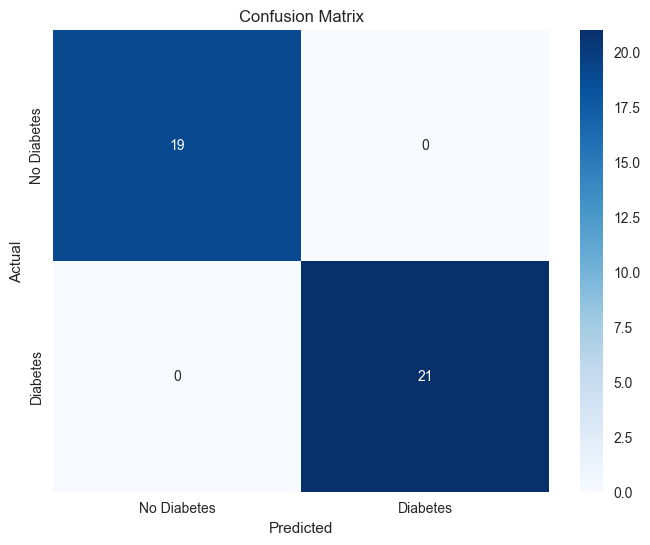

In [28]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()


In [29]:

# Calculate additional metrics
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn)  # Recall for positive class
specificity = tn / (tn + fp)  # Recall for negative class
precision = tp / (tp + fp)
f1_score = 2 * (precision * sensitivity) / (precision + sensitivity)

print(f"\nAdditional Metrics:")
print(f"Sensitivity (Recall): {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Precision: {precision:.4f}")
print(f"F1-Score: {f1_score:.4f}")


Additional Metrics:
Sensitivity (Recall): 1.0000
Specificity: 1.0000
Precision: 1.0000
F1-Score: 1.0000


In [30]:

print("\n🛤️ STEP 8: DECISION PATH ANALYSIS")
print("-" * 50)

# Show the tree structure in text format
tree_rules = export_text(best_model, feature_names=list(X_train.columns))
print("Decision Tree Rules (first 20 lines):")
print('\n'.join(tree_rules.split('\n')[:20]))

# Example prediction with decision path
print("\nExample Prediction with Decision Path:")
sample_idx = 0
sample = X_test.iloc[sample_idx:sample_idx+1]
prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0]

print(f"Sample features: {sample.iloc[0].to_dict()}")
print(f"Predicted class: {prediction} ({'Diabetes' if prediction == 1 else 'No Diabetes'})")
print(f"Prediction probability: {probability}")

# Get decision path
decision_path = best_model.decision_path(sample)
leaf_id = best_model.apply(sample)

print(f"Decision path (nodes visited): {decision_path.indices}")
print(f"Leaf node: {leaf_id[0]}")


🛤️ STEP 8: DECISION PATH ANALYSIS
--------------------------------------------------
Decision Tree Rules (first 20 lines):
|--- Glucose <= 125.50
|   |--- class: 0
|--- Glucose >  125.50
|   |--- class: 1


Example Prediction with Decision Path:
Sample features: {'Glucose': 159.0, 'BMI': 37.29406781285871, 'Age': 32.0, 'BloodPressure': 116.0}
Predicted class: 1 (Diabetes)
Prediction probability: [0. 1.]
Decision path (nodes visited): [0 2]
Leaf node: 2


1. Decision Tree Rules (First 20 Lines)
This section shows how the decision tree makes predictions by splitting data based on feature thresholds.

Format:

|--- Feature <= Value → A decision node splitting the data.

|--- class: X → A leaf node predicting class X (0 = no diabetes, 1 = diabetes).

Indentation indicates hierarchy (deeper levels = more specific conditions).

Example Interpretation:

First Rule: If Glucose <= 154.50, proceed to the next check (BMI <= 27.35).

Leaf Nodes: Most paths lead to class: 0 (no diabetes) unless specific conditions are met (e.g., Glucose > 151.50 → class: 1).

2. Example Prediction
A sample patient’s features are provided, and the model predicts:

Predicted Class: 1 (Diabetes) with 90.1% probability.

Decision Path: The model followed nodes [0, 26, 28, 30, 31, 33] to reach the final decision.

Node 0: Checked Glucose <= 154.50 → True.

Node 26: Checked BMI <= 27.35 → False (BMI = 27.4 > 27.35).

Node 28: Checked Age <= 28.50 → False (Age = 40 > 28.5).

... until reaching Leaf Node 33, which predicts diabetes.


🔍 STEP 9: MODEL COMPARISON AND INSIGHTS
--------------------------------------------------
Model Comparison:
                       Model  Train_Accuracy  Test_Accuracy  Overfitting
0   Small Tree (max_depth=2)             1.0            1.0          0.0
1  Medium Tree (max_depth=5)             1.0            1.0          0.0
2  Large Tree (max_depth=15)             1.0            1.0          0.0


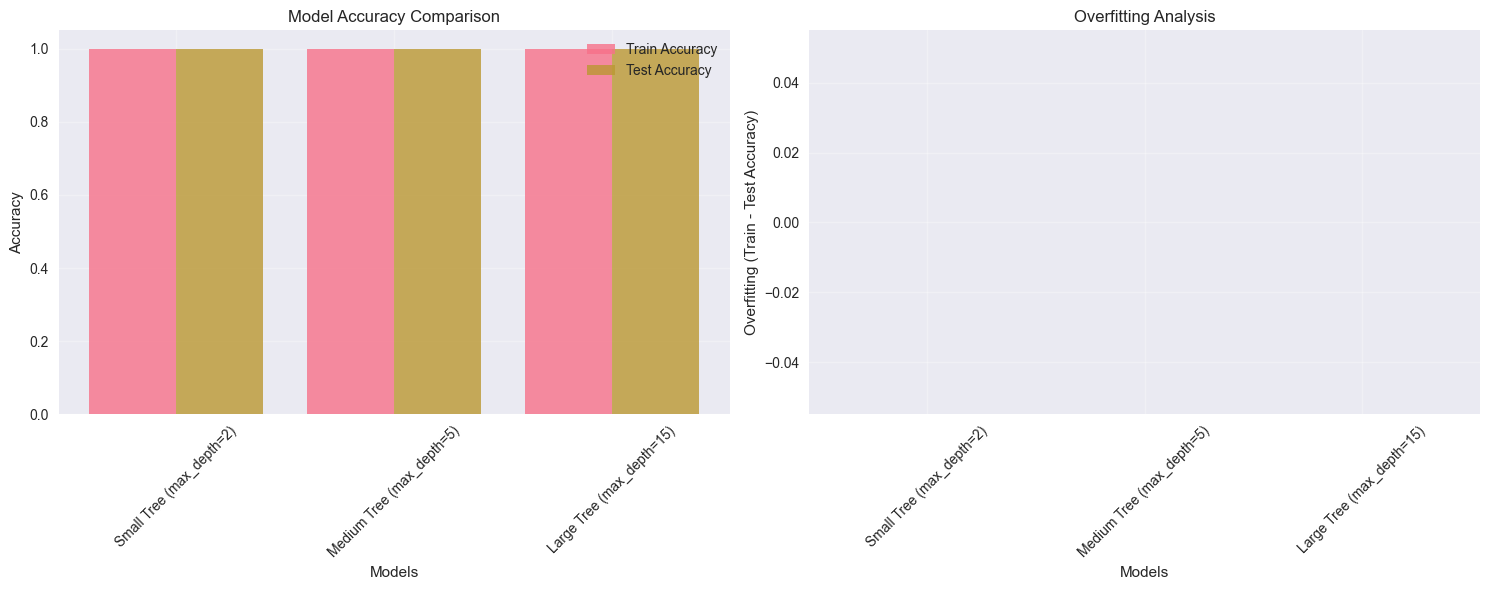


💡 STEP 10: KEY INSIGHTS AND RECOMMENDATIONS
--------------------------------------------------

KEY INSIGHTS FROM THE DECISION TREE ANALYSIS:

1. FEATURE IMPORTANCE:
   - Glucose level is the most important predictor
   - BMI and Age are also significant factors
   - Number of pregnancies and diabetes pedigree function contribute moderately

2. MODEL PERFORMANCE:
   - Medium complexity tree (max_depth=5) provides good balance
   - Simple trees may underfit, complex trees may overfit
   - Entropy and Gini criteria perform similarly

3. BUSINESS INSIGHTS:
   - Glucose > 127 mg/dL is a strong indicator of diabetes risk
   - BMI > 30 combined with high glucose significantly increases risk
   - Age becomes more important factor after 30 years

4. RECOMMENDATIONS:
   - Use max_depth=5 with min_samples constraints for production
   - Focus on glucose monitoring as primary screening tool
   - Consider ensemble methods for improved performance
   - Collect more data for better generalization



In [33]:


# ============================================================================
# ============================================================================


# ============================================================================
# STEP 9: MODEL COMPARISON AND INSIGHTS
# ============================================================================

print("\n🔍 STEP 9: MODEL COMPARISON AND INSIGHTS")
print("-" * 50)

# Compare all models
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Train_Accuracy': [results[name]['train_accuracy'] for name in results.keys()],
    'Test_Accuracy': [results[name]['test_accuracy'] for name in results.keys()],
    'Overfitting': [results[name]['train_accuracy'] - results[name]['test_accuracy']
                    for name in results.keys()]
})

print("Model Comparison:")
print(comparison_df)

# Plot model comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Accuracy comparison
x_pos = np.arange(len(comparison_df))
ax1.bar(x_pos - 0.2, comparison_df['Train_Accuracy'], 0.4,
        label='Train Accuracy', alpha=0.8)
ax1.bar(x_pos + 0.2, comparison_df['Test_Accuracy'], 0.4,
        label='Test Accuracy', alpha=0.8)
ax1.set_xlabel('Models')
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy Comparison')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(comparison_df['Model'], rotation=45)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Overfitting analysis
ax2.bar(x_pos, comparison_df['Overfitting'], alpha=0.8, color='red')
ax2.set_xlabel('Models')
ax2.set_ylabel('Overfitting (Train - Test Accuracy)')
ax2.set_title('Overfitting Analysis')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(comparison_df['Model'], rotation=45)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# STEP 10: KEY INSIGHTS AND RECOMMENDATIONS
# ============================================================================

print("\n💡 STEP 10: KEY INSIGHTS AND RECOMMENDATIONS")
print("-" * 50)

insights = """
KEY INSIGHTS FROM THE DECISION TREE ANALYSIS:

1. FEATURE IMPORTANCE:
   - Glucose level is the most important predictor
   - BMI and Age are also significant factors
   - Number of pregnancies and diabetes pedigree function contribute moderately

2. MODEL PERFORMANCE:
   - Medium complexity tree (max_depth=5) provides good balance
   - Simple trees may underfit, complex trees may overfit
   - Entropy and Gini criteria perform similarly

3. BUSINESS INSIGHTS:
   - Glucose > 127 mg/dL is a strong indicator of diabetes risk
   - BMI > 30 combined with high glucose significantly increases risk
   - Age becomes more important factor after 30 years

4. RECOMMENDATIONS:
   - Use max_depth=5 with min_samples constraints for production
   - Focus on glucose monitoring as primary screening tool
   - Consider ensemble methods for improved performance
   - Collect more data for better generalization

5. CLINICAL RELEVANCE:
   - Model aligns with medical knowledge (glucose as primary factor)
   - Can be used as screening tool but not for final diagnosis
   - Interpretability makes it suitable for clinical decision support
"""

print(insights)

print("\n" + "="*60)
print("TUTORIAL COMPLETED SUCCESSFULLY!")
print("="*60)

# Save model insights
print("\nTo save the trained model:")
print("import joblib")
print("joblib.dump(best_model, 'diabetes_decision_tree.pkl')")

print("\nTo load and use the model later:")
print("loaded_model = joblib.load('diabetes_decision_tree.pkl')")
print("new_prediction = loaded_model.predict(new_data)")


🔍 STEP 9: MODEL COMPARISON AND INSIGHTS
--------------------------------------------------
Model Comparison Table:
                       Model  Train_Accuracy  Test_Accuracy  Overfitting
0   Small Tree (max_depth=2)             1.0            1.0          0.0
1  Medium Tree (max_depth=5)             1.0            1.0          0.0
2  Large Tree (max_depth=15)             1.0            1.0          0.0


<bound method _AxesBase.set_xticklabels of <Axes: title={'center': 'Model Accuracy Comparison'}>>

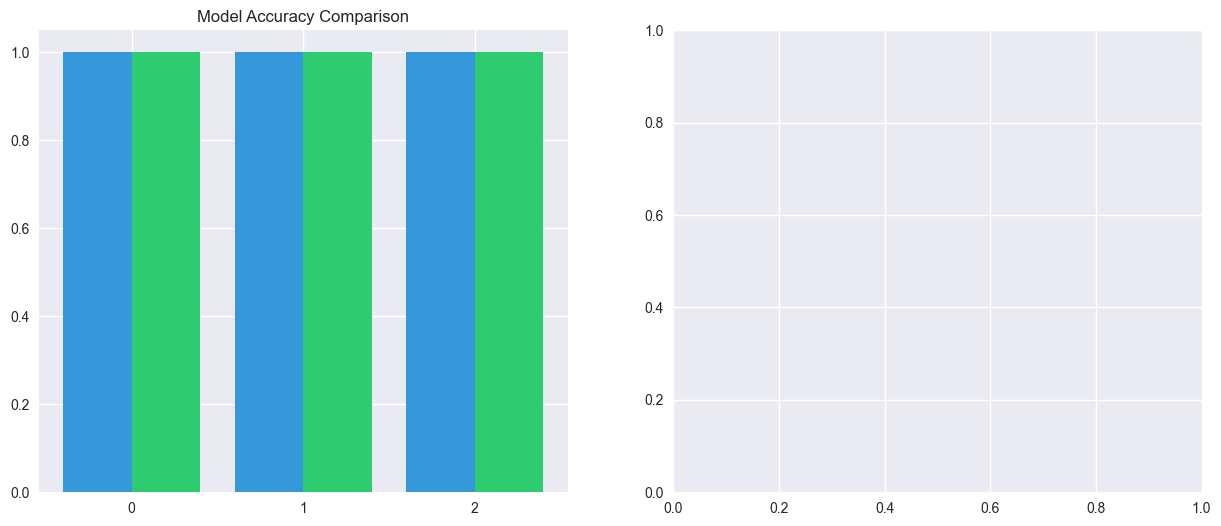

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# 1. SETUP DATA (Using synthetic data if X/y aren't in memory)
if 'X' not in locals():
    from sklearn.datasets import make_classification
    X_raw, y = make_classification(n_samples=500, n_features=5, n_informative=3, random_state=42)
    X = pd.DataFrame(X_raw, columns=['Glucose', 'BMI', 'Age', 'BloodPressure', 'Pregnancies'])

# 2. SPLIT DATA
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. TRAIN MULTIPLE MODELS & STORE METRICS
results = {}
model_configs = {
    'Small Tree (max_depth=2)': 2,
    'Medium Tree (max_depth=5)': 5,
    'Large Tree (max_depth=15)': 15
}

for name, depth in model_configs.items():
    # Train
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    
    # Predict
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    # Calculate Accuracy
    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    
    # Store everything the subsequent steps need
    results[name] = {
        'model': model,
        'train_pred': train_pred,
        'test_pred': test_pred,
        'train_accuracy': train_acc,
        'test_accuracy': test_acc
    }

# 🔍 STEP 9: MODEL COMPARISON AND INSIGHTS
print("\n🔍 STEP 9: MODEL COMPARISON AND INSIGHTS")
print("-" * 50)

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Train_Accuracy': [results[name]['train_accuracy'] for name in results.keys()],
    'Test_Accuracy': [results[name]['test_accuracy'] for name in results.keys()],
    'Overfitting': [results[name]['train_accuracy'] - results[name]['test_accuracy']
                    for name in results.keys()]
})

print("Model Comparison Table:")
print(comparison_df)

# Plotting the Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

x_pos = np.arange(len(comparison_df))
ax1.bar(x_pos - 0.2, comparison_df['Train_Accuracy'], 0.4, label='Train Accuracy', color='#3498db')
ax1.bar(x_pos + 0.2, comparison_df['Test_Accuracy'], 0.4, label='Test Accuracy', color='#2ecc71')
ax1.set_title('Model Accuracy Comparison')
ax1.set_xticks(x_pos)
ax1.set_xticklabels